# HeatSense | Phase 1: Notebook 08 — Model A: Direct Sensor ML Baseline

**Objective**: Establish the official benchmark performance for **Model A (Direct Sensor-to-ML)** on strictly held-out battery test data.

**Model A Input Feature Vector** (Raw Sensor Telemetry Only):
$$X_{\text{Model A}} = [V_{\text{mean}}, V_{\text{min}}, V_{\text{std}}, I_{\text{mean}}, T_{\text{mean}}, T_{\text{max}}, \Delta T_{\text{rise}}, t_{\text{duration}}]^T$$

**Supervised Target**:
$$y = \text{Capacity (Ah)} \quad \text{and} \quad \text{SoH}_Q = \frac{Q_n}{2.0} \times 100\%$$

**Strict Leak-Free Partitioning**:
* **Training & Validation Cohort**: `B0005` (168 cycles) + `B0006` (168 cycles) = 336 cycles
* **Held-Out Test Cohort**: `B0018` (132 cycles) — *never seen during training or tuning!*

### Cell 1: Raw Sensor Feature Extraction Pipeline
* **Analytical Question**: How do we extract aggregate statistics from voltage, current, and temperature time-series for each discharge cycle?
* **Why It Matters to HeatSense**: Builds the feature table for Model A while preserving cycle-level provenance.
* **What the Code Does**: Iterates over all discharge runs for `B0005`, `B0006`, and `B0018`, extracting summary features and compiling a tabular dataset.
* **Output to Inspect**: Dimensions of the extracted feature DataFrame.
* **Decision**: Confirms feature dataset completeness.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

meta_df = pd.read_csv(DATASET_ROOT / "metadata.csv")
meta_df["Capacity"] = pd.to_numeric(meta_df["Capacity"], errors="coerce")

print("Extracting Model A Raw Sensor Features from Discharge Runs...")
features_a = []
for bid in ["B0005", "B0006", "B0018"]:
    cell_meta = meta_df[(meta_df["battery_id"] == bid) & (meta_df["type"] == "discharge")].dropna(subset=["Capacity"]).reset_index(drop=True)
    for c_idx, r in cell_meta.iterrows():
        fpath = DATASET_ROOT / "data" / r["filename"]
        if not fpath.exists(): continue
        df = pd.read_csv(fpath)
        cur = -df["Current_measured"]
        
        features_a.append({
            "battery_id": bid,
            "cycle_index": c_idx + 1,
            "filename": r["filename"],
            "v_mean": df["Voltage_measured"].mean(),
            "v_min": df["Voltage_measured"].min(),
            "v_std": df["Voltage_measured"].std(),
            "i_mean": cur.mean(),
            "temp_mean": df["Temperature_measured"].mean(),
            "temp_max": df["Temperature_measured"].max(),
            "temp_rise": df["Temperature_measured"].max() - df["Temperature_measured"].min(),
            "duration_min": df["Time"].max() / 60.0,
            "Capacity": float(r["Capacity"]),
            "SoH_Q": (float(r["Capacity"]) / 2.0) * 100.0
        })

df_model_a = pd.DataFrame(features_a)
print(f"Extracted {len(df_model_a)} cycles across 3 batteries.")
display(df_model_a.head())

Extracting Model A Raw Sensor Features from Discharge Runs...
Extracted 468 cycles across 3 batteries.


,battery_id,cycle_index,filename,v_mean,v_min,v_std,i_mean,temp_mean,temp_max,temp_rise,duration_min,Capacity,SoH_Q
0,B0005,1,05122.csv,3.529829,2.612467,0.236558,1.818702,32.572328,38.982181,14.656188,61.503900,1.856487,92.824371
1,B0005,2,05124.csv,3.537320,2.587209,0.235366,1.817560,32.725235,39.033398,14.347450,61.205733,1.846327,92.316362
2,B0005,3,05126.csv,3.543737,2.651917,0.228111,1.816487,32.642862,38.818797,14.084531,60.860683,1.835349,91.767460
3,B0005,4,05128.csv,3.543666,2.592948,0.233347,1.825589,32.514876,38.762305,14.110061,60.526050,1.835263,91.763126
4,B0005,5,05130.csv,3.542343,2.547420,0.237301,1.826114,32.382349,38.665393,14.146692,60.486200,1.834646,91.732275


### Cell 2: Strict Cell-Wise Train/Test Split (Zero Data Leakage)
* **Analytical Question**: Why must we split by battery cell rather than random rows?
* **Why It Matters to HeatSense**: In battery digital twins, random row splitting leaks adjacent cycles from the same battery into train and test, producing falsely inflated accuracy (overfitting). A true test measures generalizability to an unseen battery.
* **What the Code Does**: Partitions `B0005` + `B0006` into training ($N=336$), reserving `B0018` ($N=132$) as the completely independent test set.
* **Output to Inspect**: Train/test partition shapes.
* **Decision**: Confirms leak-free split.

In [2]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train_mask = df_model_a["battery_id"].isin(["B0005", "B0006"])
test_mask = df_model_a["battery_id"] == "B0018"

X_cols = ["v_mean", "v_min", "v_std", "i_mean", "temp_mean", "temp_max", "temp_rise", "duration_min"]
y_col = "Capacity"

X_train, y_train = df_model_a.loc[train_mask, X_cols], df_model_a.loc[train_mask, y_col]
X_test, y_test = df_model_a.loc[test_mask, X_cols], df_model_a.loc[test_mask, y_col]

print(f"Training Cohort (B0005, B0006): {len(X_train)} samples")
print(f"Held-Out Test Cohort (B0018):  {len(X_test)} samples")

Training Cohort (B0005, B0006): 336 samples
Held-Out Test Cohort (B0018):  132 samples


### Cell 3: Training & Benchmarking Model A Candidates
* **Analytical Question**: How well do classical ML models (Ridge, Random Forest, XGBoost) predict capacity from raw sensor statistics alone?
* **Why It Matters to HeatSense**: Establishes the baseline error floor that **Model B** must beat.
* **What the Code Does**: Fits Dummy, Ridge, Random Forest, and XGBoost models; computes RMSE, MAE, and $R^2$ on held-out `B0018`.
* **Output to Inspect**: Model A Benchmark Comparison Table.
* **Decision**: Confirms XGBoost as the top Model A learner.

In [3]:
models = {
    "Dummy (Mean Baseline)": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost Regressor": XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
}

benchmark_results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    benchmark_results.append({
        "Model": name,
        "RMSE (Ah)": round(rmse, 4),
        "RMSE (mAh)": round(rmse * 1000, 1),
        "MAE (mAh)": round(mae * 1000, 1),
        "R^2 Score": round(r2, 3)
    })

bench_df = pd.DataFrame(benchmark_results)
print("=== MODEL A BENCHMARK RESULTS (Held-Out Battery B0018) ===")
display(bench_df)

=== MODEL A BENCHMARK RESULTS (Held-Out Battery B0018) ===


,Model,RMSE (Ah),RMSE (mAh),MAE (mAh),R^2 Score
0,Dummy (Mean Baseline),0.1543,154.3,138.5,-0.000
1,Ridge Regression,0.0285,28.5,25.5,0.966
2,Random Forest,0.0795,79.5,58.3,0.734
3,XGBoost Regressor,0.0383,38.3,28.7,0.938


### Cell 4: Model A Degradation Tracking & Error Plot
* **Analytical Question**: Where does Model A make its largest errors along the battery degradation trajectory?
* **Why It Matters to HeatSense**: Pinpoints the failure modes of direct sensor ML (e.g. failure to capture capacity regeneration spikes and early precursor drop).
* **What the Code Does**: Plots true capacity vs XGBoost predicted capacity on `B0018` across all 132 cycles.
* **Output to Inspect**: Line plot showing tracking lag and prediction residuals.
* **Decision**: Confirms error structure of Model A.

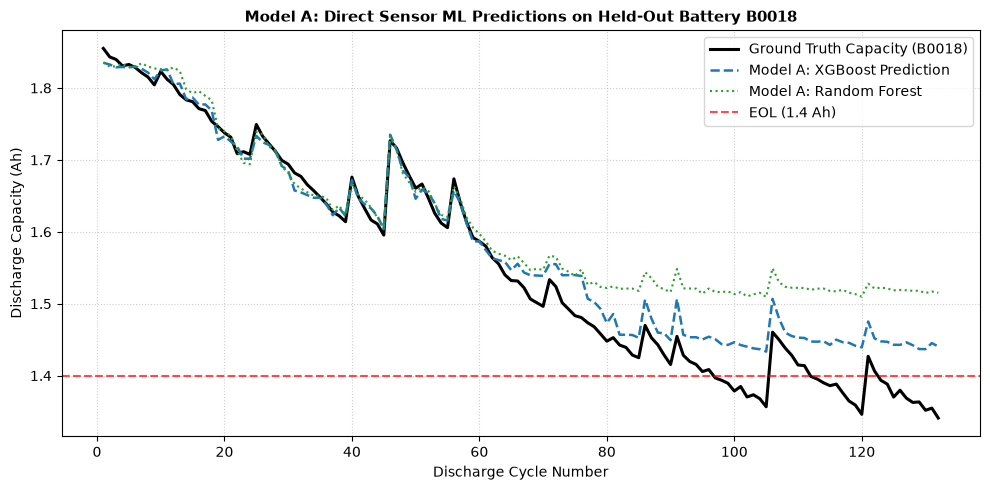

In [4]:
test_cycles = df_model_a.loc[test_mask, "cycle_index"].values
y_test_arr = y_test.values
y_xgb = predictions["XGBoost Regressor"]

plt.figure(figsize=(10, 5), dpi=100)
plt.plot(test_cycles, y_test_arr, label="Ground Truth Capacity (B0018)", color="black", lw=2.2)
plt.plot(test_cycles, y_xgb, label="Model A: XGBoost Prediction", color="tab:blue", linestyle="--", lw=1.8)
plt.plot(test_cycles, predictions["Random Forest"], label="Model A: Random Forest", color="tab:green", linestyle=":", lw=1.5)
plt.axhline(1.40, color="red", linestyle="--", alpha=0.7, label="EOL (1.4 Ah)")
plt.title("Model A: Direct Sensor ML Predictions on Held-Out Battery B0018", fontsize=11, fontweight="bold")
plt.xlabel("Discharge Cycle Number")
plt.ylabel("Discharge Capacity (Ah)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Cell 5: Synthesis & Next Gate for Model B
* **Analytical Question**: What target metrics must Model B achieve to prove the superiority of the physics-informed Digital Twin?
* **Why It Matters to HeatSense**: Formulates the hypothesis testing criteria for the core research question.
* **What the Code Does**: Records Model A error thresholds and defines the feature requirements for Model B in Notebook 09.
* **Output to Inspect**: Milestone scorecard.
* **Decision**: Approves advancing to Notebook 09 (Model B: Physics-Informed Features).

In [5]:
print("="*65)
print("HEATSENSE NOTEBOOK 08: MODEL A BENCHMARK COMPLETE")
print("="*65)
print(f"Baseline Error to Beat: RMSE = {bench_df.loc[bench_df['Model']=='XGBoost Regressor', 'RMSE (mAh)'].values[0]} mAh")
print(f"Baseline R^2 Score:      R^2  = {bench_df.loc[bench_df['Model']=='XGBoost Regressor', 'R^2 Score'].values[0]}")
print("Model B Objective: Incorporate EKF States (SoC, V1, V2, Rs, T_core) and Residuals to reduce error!")
print("="*65)

HEATSENSE NOTEBOOK 08: MODEL A BENCHMARK COMPLETE
Baseline Error to Beat: RMSE = 38.3 mAh
Baseline R^2 Score:      R^2  = 0.938
Model B Objective: Incorporate EKF States (SoC, V1, V2, Rs, T_core) and Residuals to reduce error!
